In [1]:
# Python version
import sys
print(sys.version)

3.12.13 | packaged by Anaconda, Inc. | (main, Mar 19 2026, 20:16:45) [MSC v.1942 64 bit (AMD64)]


In [2]:
# Import key libraries and check versions
import pandas as pd
import numpy as np
import sklearn
import shap
import irapy
import matplotlib

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)
print("shap:", shap.__version__)
print("irapy:", irapy.__version__)
print("matplotlib:", matplotlib.__version__)

pandas: 2.3.3
numpy: 2.2.5
sklearn: 1.8.0
shap: 0.51.0
irapy: 0.1.2
matplotlib: 3.10.9


In [3]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.inspection import PartialDependenceDisplay
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from irapy import repeated_ira
import warnings
warnings.filterwarnings("ignore")

In [4]:
n_cpus = 12

In [5]:
# Download Concrete_Data.xls from:
# https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength
df = pd.read_excel("Concrete_Data.xls")

In [6]:
df.columns = [
    "Cement",
    "Blast Furnace Slag",
    "Fly Ash",
    "Water",
    "Superplasticizer",
    "Coarse Aggregate",
    "Fine Aggregate",
    "Age",
    "Compressive Strength"
]


X = df.drop(columns=["Compressive Strength"])
y = df["Compressive Strength"]

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
Blast Furnace Slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
Fly Ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
Water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
Superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
Coarse Aggregate,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
Fine Aggregate,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
Age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
Compressive Strength,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


In [7]:
#  Train models

models = {
    'GB': GradientBoostingRegressor(random_state=42),

    'MLP': Pipeline([
        ('scaler', StandardScaler()),
        ('MLP', MLPRegressor(random_state=42, max_iter=500)),
    ]),

    'RF': RandomForestRegressor(random_state=42),

    'RR': Pipeline([
        ('scaler', StandardScaler()),
        ('RR', Ridge()),
    ]),

    'SVR': Pipeline([
        ('scaler', StandardScaler()),
        ('SVR', SVR()),
    ])
}

trained_models = {}
performance = {}

print("Model Performance (R²):")
print("-" * 50)

for name, model in models.items():
    model.fit(X, y)
    score = model.score(X,y)
    trained_models[name] = model
    performance[name] = score

print(performance)

Model Performance (R²):
--------------------------------------------------
{'GB': 0.9453656032600309, 'MLP': 0.8786114888496164, 'RF': 0.9875486710759163, 'RR': 0.61544858322636, 'SVR': 0.697170208484722}


In [8]:
# Repeated IRA

final_ira_result = []

for name, model in trained_models.items():

    repeated_ira_result = repeated_ira(input_data=X, model=model, n_jobs=n_cpus)

    print("#"*80)
    print(name)
    display(repeated_ira_result)

    sel = repeated_ira_result.iloc[:,1:].copy()
    sel.columns = [f"{name}_{col}" for col in sel.columns]
    final_ira_result.append(sel)

repeated_ira_df = pd.concat(final_ira_result, axis=1)
repeated_ira_df.insert(0,'predictor',X.columns)
print("\n--- Final Repeated IRA Result Table ---")
repeated_ira_df

################################################################################
GB


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Cement,37.990939,37.225001,38.756715
1,Blast Furnace Slag,15.275366,14.551309,15.939051
2,Fly Ash,2.341488,2.244057,2.448860
3,Water,16.279547,15.634353,16.827024
4,Superplasticizer,5.776827,5.431727,6.204063
5,Coarse Aggregate,9.047271,8.808135,9.359755
6,Fine Aggregate,6.636834,6.281573,7.075249
7,Age,36.474357,35.774466,37.154074


################################################################################
MLP


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Cement,53.613932,52.440923,54.955634
1,Blast Furnace Slag,39.383188,38.000037,40.640635
2,Fly Ash,17.625131,17.173133,18.299681
3,Water,15.664152,14.709001,16.557625
4,Superplasticizer,13.051931,12.561518,13.624991
5,Coarse Aggregate,11.880164,11.175577,12.610700
6,Fine Aggregate,11.864994,10.934359,12.910079
7,Age,36.448209,35.025050,37.717908


################################################################################
RF


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Cement,32.309490,31.101404,33.124030
1,Blast Furnace Slag,10.385790,9.606140,11.182743
2,Fly Ash,2.175936,1.971574,2.428746
3,Water,10.858454,9.918783,11.654704
4,Superplasticizer,7.060686,6.651732,7.571360
5,Coarse Aggregate,4.177674,3.864974,4.624774
6,Fine Aggregate,5.256896,4.815371,5.674153
7,Age,30.785232,29.912695,31.812896


... (2 outputs left out)

################################################################################
SVR


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Cement,18.477048,17.730521,19.233967
1,Blast Furnace Slag,9.266009,8.892893,9.669723
2,Fly Ash,5.899061,5.412048,6.358504
3,Water,13.166892,12.582841,13.637325
4,Superplasticizer,10.458658,9.886179,11.180704
5,Coarse Aggregate,6.586234,6.037798,7.161248
6,Fine Aggregate,8.558741,7.990063,9.146603
7,Age,21.271810,20.483264,22.021994



--- Final Repeated IRA Result Table ---


,predictor,GB_mean_ira,GB_ci_lower_ira,GB_ci_upper_ira,MLP_mean_ira,MLP_ci_lower_ira,MLP_ci_upper_ira,RF_mean_ira,RF_ci_lower_ira,RF_ci_upper_ira,RR_mean_ira,RR_ci_lower_ira,RR_ci_upper_ira,SVR_mean_ira,SVR_ci_lower_ira,SVR_ci_upper_ira
0,Cement,37.990939,37.225001,38.756715,53.613932,52.440923,54.955634,32.309490,31.101404,33.124030,51.723514,51.723514,51.723514,18.477048,17.730521,19.233967
1,Blast Furnace Slag,15.275366,14.551309,15.939051,39.383188,38.000037,40.640635,10.385790,9.606140,11.182743,36.602137,36.602137,36.602137,9.266009,8.892893,9.669723
2,Fly Ash,2.341488,2.244057,2.448860,17.625131,17.173133,18.299681,2.175936,1.971574,2.428746,17.115085,17.115085,17.115085,5.899061,5.412048,6.358504
3,Water,16.279547,15.634353,16.827024,15.664152,14.709001,16.557625,10.858454,9.918783,11.654704,19.518464,19.518464,19.518464,13.166892,12.582841,13.637325
4,Superplasticizer,5.776827,5.431727,6.204063,13.051931,12.561518,13.624991,7.060686,6.651732,7.571360,9.372566,9.372566,9.372566,10.458658,9.886179,11.180704
5,Coarse Aggregate,9.047271,8.808135,9.359755,11.880164,11.175577,12.610700,4.177674,3.864974,4.624774,5.671744,5.671744,5.671744,6.586234,6.037798,7.161248
6,Fine Aggregate,6.636834,6.281573,7.075249,11.864994,10.934359,12.910079,5.256896,4.815371,5.674153,7.263069,7.263069,7.263069,8.558741,7.990063,9.146603
7,Age,36.474357,35.774466,37.154074,36.448209,35.025050,37.717908,30.785232,29.912695,31.812896,41.490444,41.490444,41.490444,21.271810,20.483264,22.021994


In [9]:
# Permutation importance

importance_dict = {}
for name, model in trained_models.items():
    print(name)
    result = permutation_importance(model, X, y, n_repeats=10, scoring = 'neg_mean_absolute_error', random_state=42, n_jobs=n_cpus)
    importance_dict[(name, 'mean')] = result.importances_mean
    importance_dict[(name, 'std')] = result.importances_std

importance_df = pd.DataFrame(importance_dict, index=X.columns)
importance_df.columns = pd.MultiIndex.from_tuples(importance_df.columns)
importance_df = importance_df.sort_values(by=(list(trained_models.keys())[0], 'mean'), ascending=False)
importance_df

GB
MLP
RF
RR
SVR


GB                  MLP                  RF  \
                        mean       std       mean       std      mean   
Age                 8.582025  0.138044   7.992970  0.165465  9.664799   
Cement              7.404983  0.247046  11.357070  0.343169  8.852414   
Water               3.160713  0.119297   1.505245  0.098945  3.650472   
Blast Furnace Slag  2.537777  0.157309   6.396252  0.255269  3.607645   
Superplasticizer    1.295740  0.062402   1.270601  0.078851  2.599195   
Fine Aggregate      1.007780  0.055256   1.207526  0.067393  1.525441   
Coarse Aggregate    0.475439  0.034148   1.240286  0.093307  0.938051   
Fly Ash             0.094134  0.013485   2.726840  0.112544  0.611708   

                                    RR                 SVR            
                         std      mean       std      mean       std  
Age                 0.227342  3.233999  0.129077  3.842968  0.141285  
Cement              0.301226  8.226248  0.389600  3.224589  0.178737  
Water               0.132787  0.680334  0.067414  1.435088  0.081578  
Blast Furnace Slag  0.171585  4.657457  0.202064  1.009369  0.073244  
Superplasticizer    0.125737  0.185084  0.037333  1.341661  0.078061  
Fine Aggregate      0.045104  0.158420  0.049016  0.812590  0.090665  
Coarse Aggregate    0.026632  0.092039  0.054127  0.468211  0.059628  
Fly Ash             0.017520  2.131586  0.150965  0.610134  0.054000

In [10]:
# SHAP value

shap_dict = {}
for name, model in trained_models.items():
    print(name)
    X_sample = shap.sample(X, 200, random_state=42)
    explainer = shap.Explainer(model.predict, X_sample)
    shap_values = explainer(X_sample)
    shap_dict[(name, 'mean')] = np.abs(shap_values.values).mean(axis=0)
    shap_dict[(name, 'std')] = np.abs(shap_values.values).std(axis=0)

shap_df = pd.DataFrame(shap_dict, index=X.columns)
shap_df.columns = pd.MultiIndex.from_tuples(shap_df.columns)
shap_df

GB


ExactExplainer explainer: 201it [00:11,  6.78it/s]                         


MLP
RF


ExactExplainer explainer: 201it [00:27,  4.70it/s]                         


RR
SVR


ExactExplainer explainer: 201it [05:14,  1.62s/it]                         


GB                 MLP                  RF  \
                        mean       std      mean       std      mean   
Cement              6.264870  4.680408  9.770957  6.727175  5.973978   
Blast Furnace Slag  3.472816  1.724173  7.771705  4.526646  3.332654   
Fly Ash             0.183253  0.277548  4.230223  2.245995  0.354560   
Water               4.316276  2.118655  2.514200  1.685110  3.512378   
Superplasticizer    2.036834  1.217501  2.095186  1.289577  2.568737   
Coarse Aggregate    0.543440  0.775453  1.978996  1.632560  0.426861   
Fine Aggregate      1.213712  1.126398  1.832350  1.597455  0.972002   
Age                 7.803564  6.151805  8.160794  6.256708  7.843562   

                                    RR                 SVR            
                         std      mean       std      mean       std  
Cement              5.099945  8.790749  6.102762  4.148533  2.560566  
Blast Furnace Slag  1.956134  7.433364  4.467884  2.389330  1.267837  
Fly Ash             0.335377  5.194275  1.906973  0.673102  0.523211  
Water               1.886803  2.766284  1.957756  2.878584  1.407683  
Superplasticizer    1.506618  1.426057  1.041848  2.444760  1.466736  
Coarse Aggregate    0.514645  0.983459  0.733019  0.963007  0.681401  
Fine Aggregate      0.981326  1.086837  0.880230  1.324012  0.905101  
Age                 5.843651  4.958518  6.817841  4.468185  3.213603

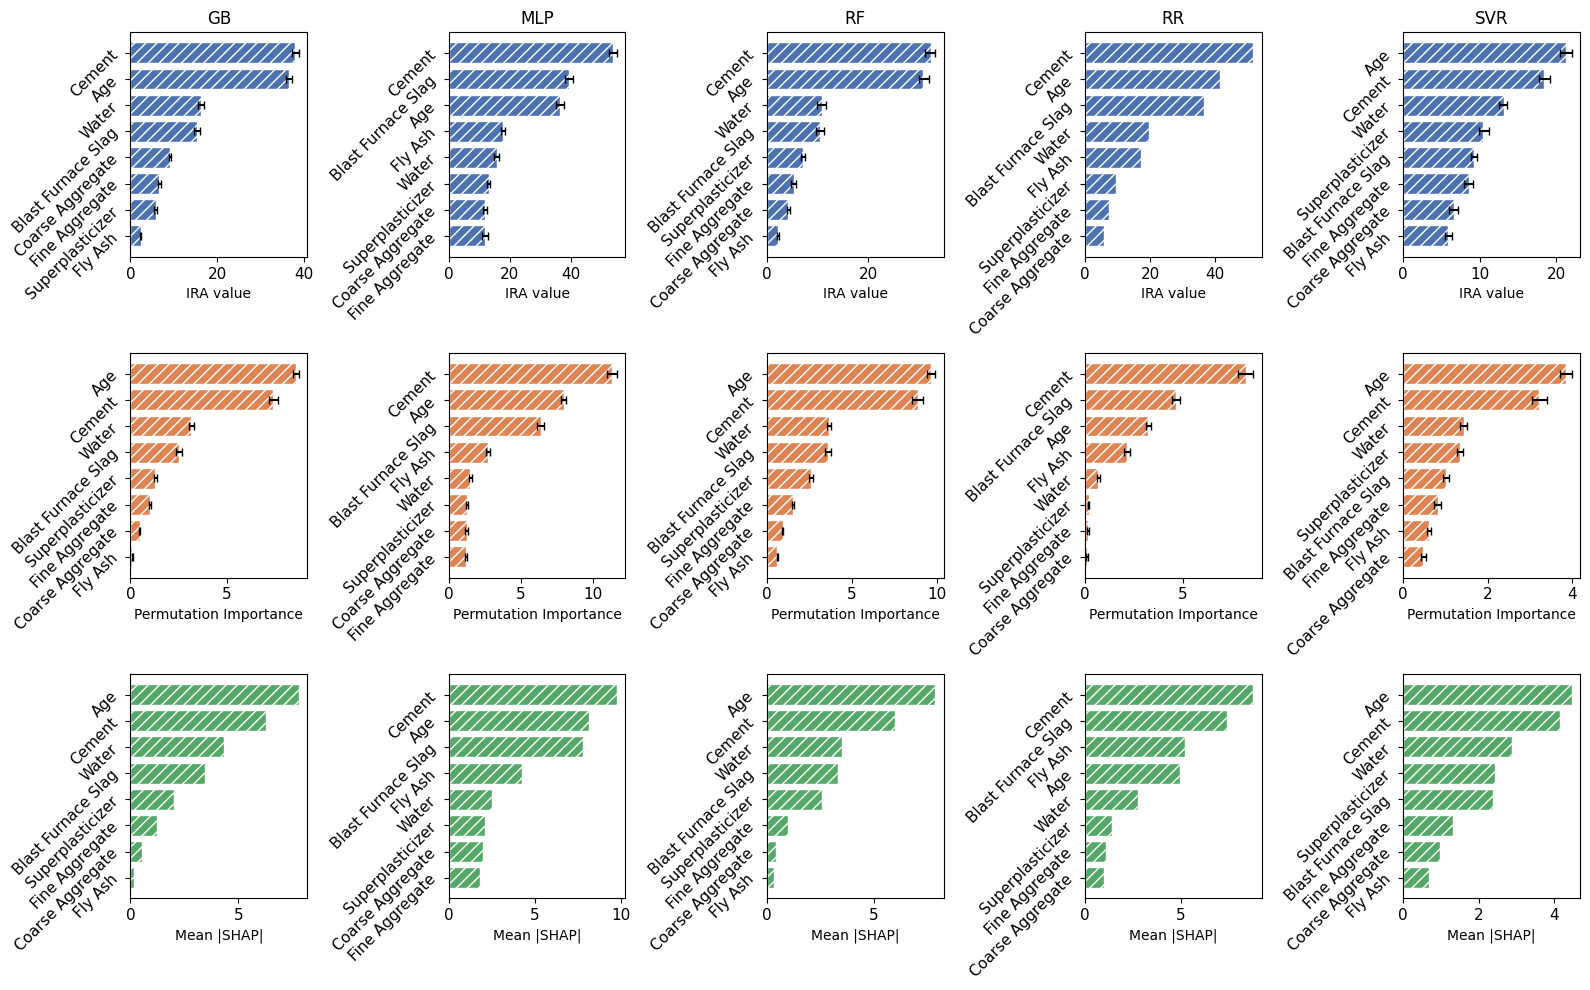

In [11]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=5,
    figsize=(16, 10),
    sharey=False,
    sharex=False
)

ira_color = "#4C72B0"
perm_color = "#DD8452"
shap_color = "#55A868"

for col, model in enumerate(models):

    # =====================================================
    # Row 1: IRA
    # =====================================================
    ira_df_plot = pd.DataFrame({
        "feature": repeated_ira_df["predictor"],
        "mean": repeated_ira_df[f"{model}_mean_ira"],
        "lower": repeated_ira_df[f"{model}_ci_lower_ira"],
        "upper": repeated_ira_df[f"{model}_ci_upper_ira"]
    })

    # SORT FEATURES
    ira_df_plot = ira_df_plot.sort_values(
        by="mean",
        ascending=False
    ).reset_index(drop=True)

    ira_mean = ira_df_plot["mean"]
    ira_lower = ira_df_plot["lower"]
    ira_upper = ira_df_plot["upper"]
    ira_features = ira_df_plot["feature"]

    if col != 3:
        ira_xerr = np.vstack([
            ira_mean - ira_lower,
            ira_upper - ira_mean
        ])

        bars0 = axes[0, col].barh(
            ira_features,
            ira_mean,
            xerr=ira_xerr,
            capsize=3,
            color=ira_color,
            edgecolor='white'
        )
    else:
        bars0 = axes[0, col].barh(
            ira_features,
            ira_mean,
            color=ira_color,
            edgecolor='white'
        )

    for bar in bars0:
        bar.set_hatch('///')

    axes[0, col].set_title(model)
    axes[0, col].set_xlabel('IRA value')

    # =====================================================
    # Row 2: Permutation Importance
    # =====================================================
    perm_df_plot = pd.DataFrame({
        "feature": importance_df.index,
        "mean": importance_df[(model, "mean")].values,
        "std": importance_df[(model, "std")].values
    })

    # SORT FEATURES
    perm_df_plot = perm_df_plot.sort_values(
        by="mean",
        ascending=False
    ).reset_index(drop=True)

    perm_features = perm_df_plot["feature"]
    perm_mean = perm_df_plot["mean"]
    perm_std = perm_df_plot["std"]

    bars1 = axes[1, col].barh(
        perm_features,
        perm_mean,
        xerr=perm_std,
        capsize=3,
        color=perm_color,
        edgecolor='white'
    )

    for bar in bars1:
        bar.set_hatch('///')

    axes[1, col].set_xlabel('Permutation Importance')

    # =====================================================
    # Row 3: SHAP
    # =====================================================
    shap_df_plot = pd.DataFrame({
        "feature": shap_df.index,
        "mean": shap_df[(model, "mean")].values
    })

    # SORT FEATURES
    shap_df_plot = shap_df_plot.sort_values(
        by="mean",
        ascending=False
    ).reset_index(drop=True)

    shap_features = shap_df_plot["feature"]
    shap_mean = shap_df_plot["mean"]

    bars2 = axes[2, col].barh(
        shap_features,
        shap_mean,
        color=shap_color,
        edgecolor='white'
    )

    for bar in bars2:
        bar.set_hatch('///')

    axes[2, col].set_xlabel('Mean |SHAP|')

# =====================================================
# Formatting
# =====================================================
for ax in axes.flatten():

    ax.tick_params(axis="both", labelsize=11)

    ax.tick_params(
        axis='y',
        labelrotation=45
    )

    # highest feature on top
    ax.invert_yaxis()

plt.tight_layout()

plt.savefig(
    'Concrete_compressive_strength_comparison.jpg',
    dpi=500,
    bbox_inches='tight'
)

plt.show()

GB
MLP
RF
RR
SVR


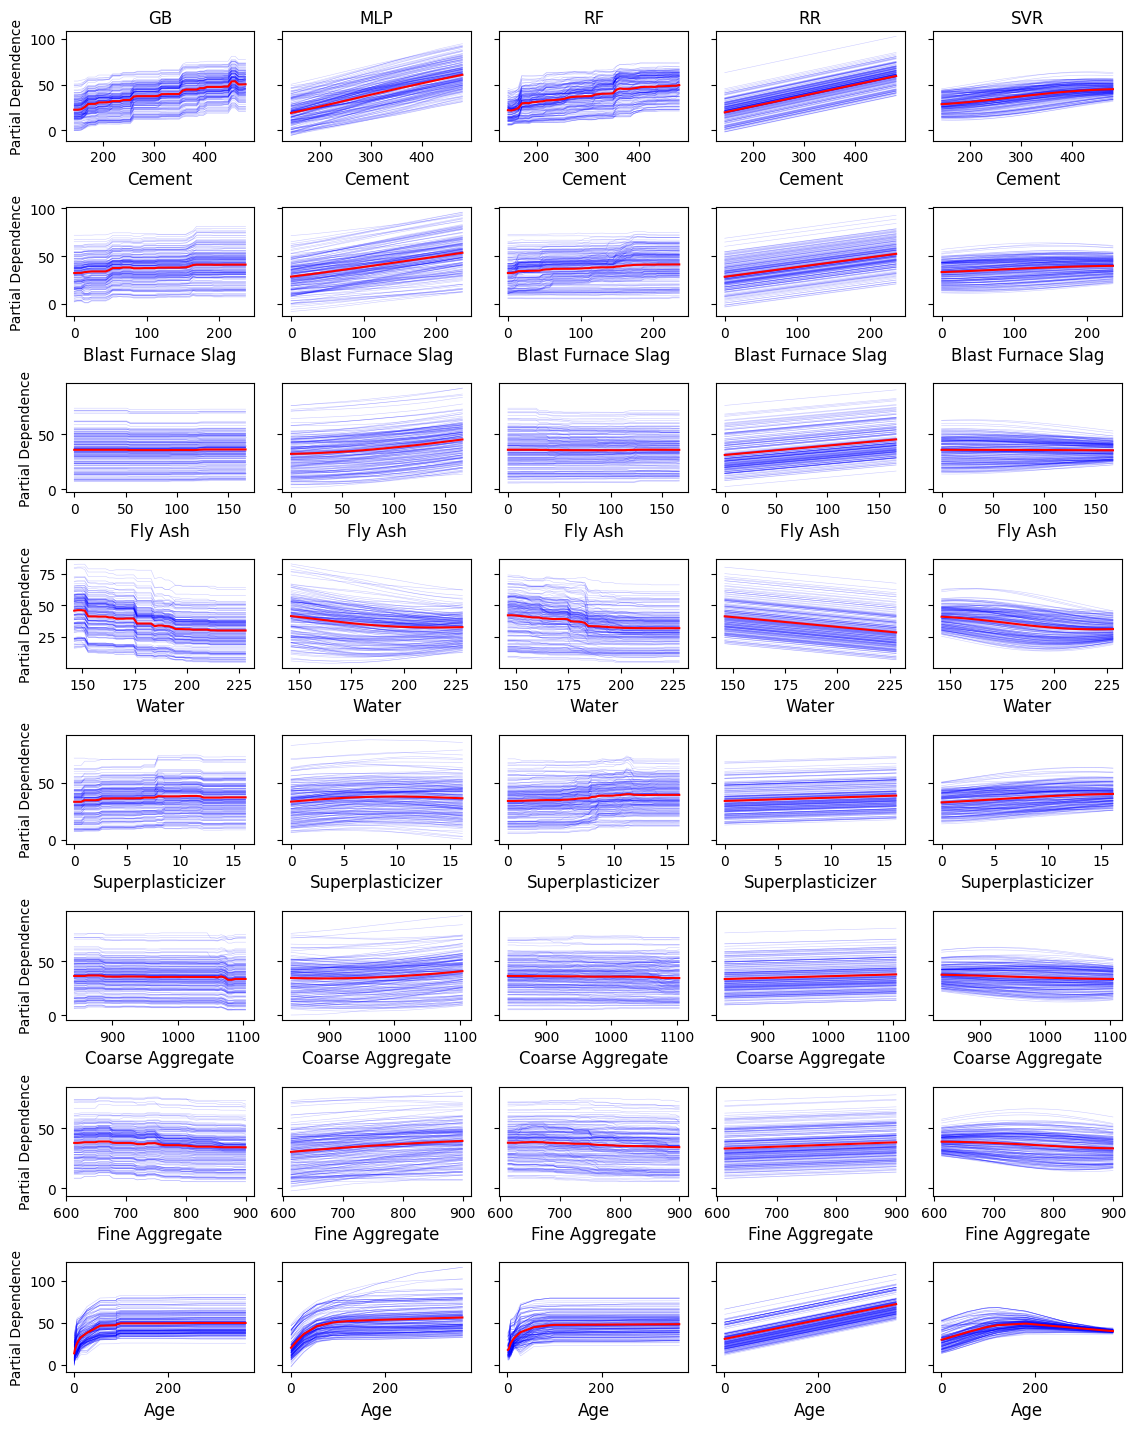

In [12]:
model_names = list(trained_models.keys())
feature_names = X.columns.tolist()
feature_indices = list(range(len(feature_names)))

# ── Generate and save PDP ──
disp_collection = {}

for name, model in trained_models.items():
    print(name)
    disp = PartialDependenceDisplay.from_estimator(
        model,
        X,
        features=feature_indices,
        feature_names=feature_names,
        subsample=200,
        kind='both',
        grid_resolution=50,
        random_state=42,
        line_kw={'color': 'red', 'linewidth': 1.5},
        ice_lines_kw={'color': 'blue', 'alpha': 0.2, 'linewidth': 0.4}
    )
    disp_collection[name] = disp
    plt.close()

# ── Plot combined figure ──
n_features = len(feature_names)
n_models = len(model_names)

fig, axes = plt.subplots(
    nrows=n_features,
    ncols=n_models,
    figsize=(2.3*n_models, 1.8*n_features),
    sharey='row'
)

for col_idx, model_name in enumerate(model_names):
    old_disp = disp_collection[model_name]
    old_axes = old_disp.axes_.flatten()

    for row_idx in range(n_features):
        old_ax = old_axes[row_idx]
        new_ax = axes[row_idx, col_idx]

        for line in old_ax.lines:
            new_ax.plot(
                line.get_xdata(),
                line.get_ydata(),
                color=line.get_color(),
                linewidth=line.get_linewidth(),
                alpha=line.get_alpha()
            )

        if row_idx == 0:
            new_ax.set_title(model_name, fontsize=12)

        new_ax.set_xlabel(feature_names[row_idx], fontsize=12)

        if col_idx == 0:
            new_ax.set_ylabel("Partial Dependence")

plt.tight_layout()
plt.savefig('Concrete_compressive_strength_PDP_ICE.jpg',dpi=500)